# Лабораторная работа 2. Классификация. Нейронные сети

**Данные:** Heart Failure Clinical Data — 299 пациентов, 12 клинических признаков,
бинарная целевая переменная `DEATH_EVENT`: 1 — летальный исход, 0 — выживание.
Классы несбалансированы (≈32% смертей, ≈68% выживших), что необходимо учитывать при выборе метрик.

**Цель:** сравнить четыре варианта Naive Bayes, пять классических классификаторов
до и после настройки и полносвязные сети TensorFlow/Keras.

Внешнее стратифицированное разбиение 80/20 фиксировано. Настройка выполняется только
на обучающих данных; внутри каждого CV-фолда заново обучаются импутер и скейлер.
Выбор нейросети использует отдельную внутреннюю валидацию.


In [34]:
RANDOM_STATE = 42
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import random, warnings
warnings.filterwarnings("ignore")
import shutil, tempfile, hashlib, platform, time
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn
import kagglehub
from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
tf.config.experimental.enable_op_determinism()
tf.get_logger().setLevel("ERROR")
thread_limit = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
pd.set_option("display.max_columns", 25)
CLASSES = np.array([0, 1])
METRICS = ["Accuracy", "Precision", "Recall", "F1-macro", "ROC-AUC"]
ANALYSIS = {}
ARTIFACTS = Path("artifacts"); ARTIFACTS.mkdir(exist_ok=True)
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
TB_WORKDIR = Path.cwd()
if os.name == "nt" and not str(TB_WORKDIR).isascii():
    TB_WORKDIR = Path(tempfile.mkdtemp(prefix="lab2_tensorboard_"))
TB_LOGROOT = TB_WORKDIR / "logs" / "fit"
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "TensorFlow": tf.__version__}
display(pd.Series(versions, name="Версия").to_frame())
ANALYSIS["setup"] = (
    f"Зафиксированы RANDOM_STATE={RANDOM_STATE} и генераторы NumPy, Python и TensorFlow. "
    f"Расчёт выполнен на Python {versions['Python']}, scikit-learn {sklearn.__version__} "
    f"и TensorFlow {tf.__version__}. Детерминированные операции и один вычислительный поток "
    "снижают вариативность; между платформами и версиями библиотек побитовая идентичность "
    "не гарантируется.")


,Версия
Python,3.13.18
NumPy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
TensorFlow,2.21.0


### Интерпретация результатов

Зафиксированы RANDOM_STATE=42 и генераторы NumPy, Python и TensorFlow. Детерминированные
операции и один вычислительный поток снижают вариативность; между платформами и версиями
библиотек побитовая идентичность не гарантируется. Все модели с параметром random_state
получают одну константу.


## 1. Загрузка и разведочный анализ данных

In [35]:
dataset_path = Path(kagglehub.dataset_download("andrewmvd/heart-failure-clinical-data"))
csv_path = dataset_path / "heart_failure_clinical_records_dataset.csv"
df = pd.read_csv(csv_path)
FEATURES = ["age", "anaemia", "creatinine_phosphokinase", "diabetes", "ejection_fraction",
            "high_blood_pressure", "platelets", "serum_creatinine", "serum_sodium",
            "sex", "smoking", "time"]
TARGET = "DEATH_EVENT"
assert set(df.columns) == set(FEATURES + [TARGET])
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)
assert not np.isinf(df.select_dtypes(include=np.number).to_numpy()).any()
assert df[TARGET].notna().all() and set(df[TARGET]) == {0, 1}
binary_columns = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]
assert all(set(df[c].dropna().unique()) <= {0, 1} for c in binary_columns)
dataset_sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
display(df.head())
df.info()
display(df.describe().T)
ANALYSIS["data"] = (
    f"Загружены {len(df)} наблюдений и {len(FEATURES)} входных признаков; "
    f"целевая переменная содержит {df[TARGET].nunique()} класса (0 — выживание, 1 — смерть). "
    f"Возраст пациентов от {df.age.min():.0f} до {df.age.max():.0f} лет, фракция выброса — "
    f"от {df.ejection_fraction.min():.0f}% до {df.ejection_fraction.max():.0f}%. "
    "Масштабы признаков различаются на порядки (креатинин — единицы, тромбоциты — сотни тысяч), "
    "поэтому расстояния и градиентная оптимизация требуют масштабирования. "
    "Пять бинарных характеристик проверены на принадлежность {0, 1}. "
    f"SHA-256 исходного CSV: `{dataset_sha256}`.")


Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


### Интерпретация результатов

Загружены 299 наблюдений и 12 входных признаков; целевая переменная бинарна
(0 — выживание, 1 — смерть). Возраст пациентов от 40 до 95 лет, фракция выброса —
от 14% до 80%. Масштабы признаков различаются на порядки (креатинин — единицы,
тромбоциты — сотни тысяч), поэтому расстояния и градиентная оптимизация требуют
масштабирования. Пять бинарных характеристик проверены на принадлежность {0, 1}.


In [36]:
missing = df.isnull().sum()
duplicates = int(df.duplicated().sum())
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "NaN": missing}))
print("Полных дубликатов:", duplicates)
if duplicates:
    df = df.drop_duplicates().reset_index(drop=True)
ANALYSIS["quality"] = (
    f"Программная верификация показала {int(missing.sum())} пропущенных значений "
    f"во всех {len(df.columns)} столбцах и {duplicates} полных дубликатов. "
    "Признаки не требуют искусственной импутации, данные переходят к масштабированию. "
    "Защитный SimpleImputer(strategy='median') сохраняется в каждом пайплайне.")


,dtype,NaN
age,float64,0
anaemia,int64,0
creatinine_phosphokinase,int64,0
diabetes,int64,0
ejection_fraction,int64,0
high_blood_pressure,int64,0
platelets,float64,0
serum_creatinine,float64,0
serum_sodium,int64,0
sex,int64,0


Полных дубликатов: 0


### Интерпретация результатов

Пропусков и дубликатов нет. Защитный `SimpleImputer(strategy='median')` сохраняется
в каждом пайплайне; его статистики не используют тест. Нулевые значения (например,
тромбоциты) не заменяются автоматически без документации о механизме измерения.


,Количество
DEATH_EVENT,
0,203
1,96


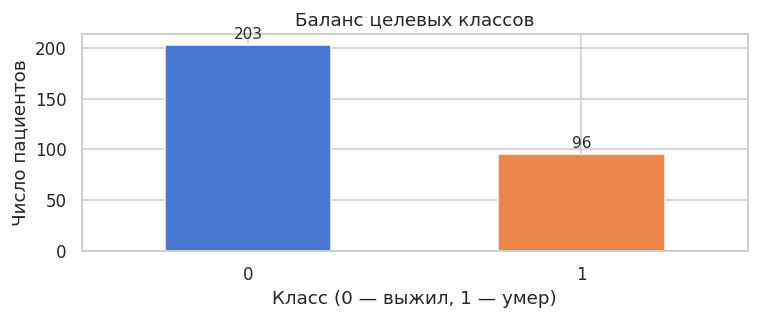

In [37]:
counts = df[TARGET].value_counts().sort_index()
display(counts.rename("Количество").to_frame())
ax = counts.plot.bar(rot=0, figsize=(7, 3), color=sns.color_palette("muted", 2))
ax.set(xlabel="Класс (0 — выжил, 1 — умер)", ylabel="Число пациентов",
       title="Баланс целевых классов")
for i, v in enumerate(counts):
    ax.text(i, v + 5, str(v), ha="center")
plt.tight_layout(); plt.show()
ANALYSIS["balance"] = (
    f"Численности классов: 0 — {counts[0]}, 1 — {counts[1]}, доли: "
    f"{(counts / len(df)).round(3).tolist()}. Классы несбалансированы. "
    "Константное предсказание «выживет» даёт точность около 0.68, но не выявляет "
    "ни одного умершего. Для сравнения моделей используем macro-F1 и ROC-AUC, "
    "а также отдельно анализируем recall класса 1.")


### Интерпретация результатов

Классы несбалансированы (≈68% выживших, ≈32% умерших). Accuracy может быть обманчива:
константное предсказание «выживет» даёт точность около 0.68, но не выявляет ни одного
умершего. Для сравнения моделей используем macro-F1 и ROC-AUC, отдельно анализируем
recall класса 1.


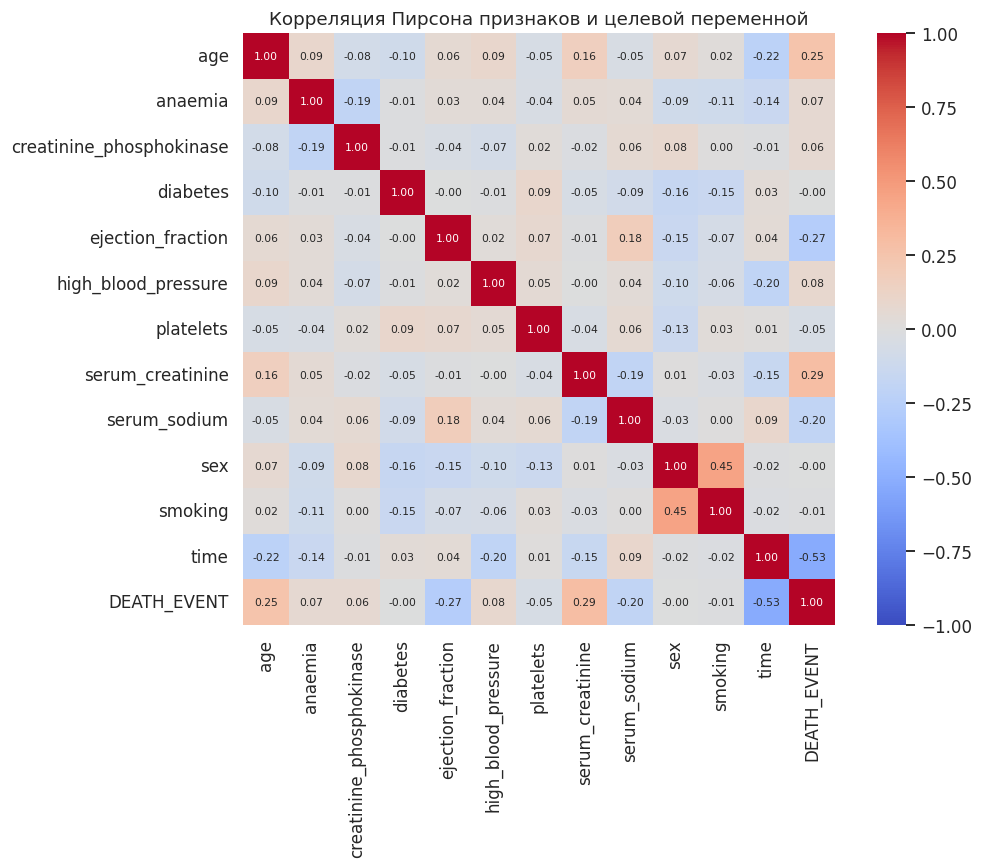

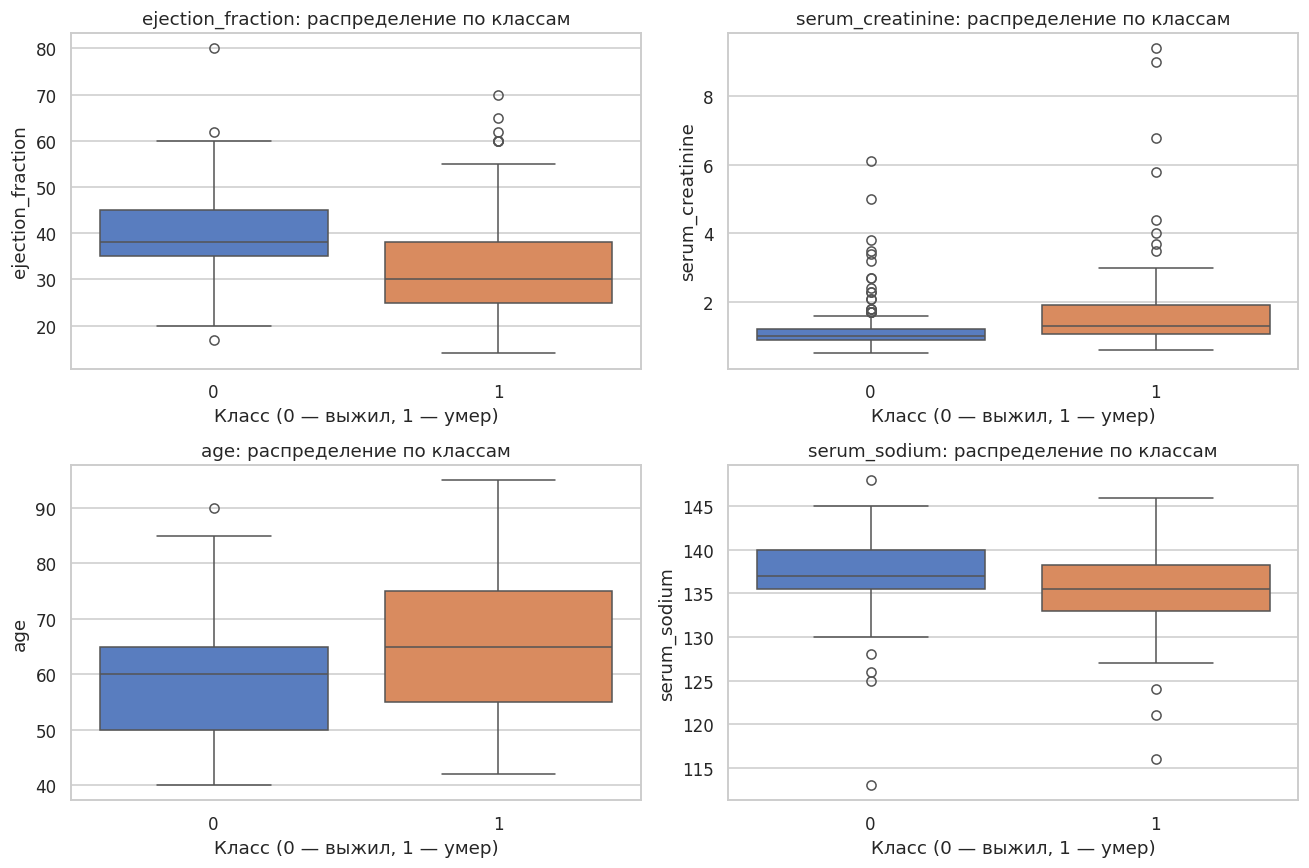

,r с DEATH_EVENT
time,-0.526964
serum_creatinine,0.294278
ejection_fraction,-0.268603
age,0.253729
serum_sodium,-0.195204
high_blood_pressure,0.079351
anaemia,0.066270
creatinine_phosphokinase,0.062728


In [38]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax,
            annot=True, fmt=".2f", annot_kws={"fontsize": 7}, square=True)
ax.set_title("Корреляция Пирсона признаков и целевой переменной")
plt.tight_layout(); plt.show()
key_features = ["ejection_fraction", "serum_creatinine", "age", "serum_sodium"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(key_features, axes.flat):
    sns.boxplot(data=df, x=TARGET, y=feature, hue=TARGET, legend=False, ax=ax)
    ax.set(xlabel="Класс (0 — выжил, 1 — умер)", ylabel=feature,
           title=f"{feature}: распределение по классам")
plt.tight_layout(); plt.show()
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(target_corr.head(8).rename("r с DEATH_EVENT").to_frame())
ANALYSIS["correlation"] = (
    "Линейные корреляции с целевой переменной: "
    + "; ".join(f"{c}: r={corr.loc[c, TARGET]:.4f}" for c in key_features) + ". "
    f"Наибольшая абсолютная корреляция у {target_corr.index[0]} "
    f"(|r|={abs(target_corr.iloc[0]):.4f}). Увеличение фракции выброса и снижение "
    "креатинина ассоциированы с выживанием; возраст и уровень натрия вносят "
    "дополнительный вклад. Корреляция не доказывает причинность. EDA носит "
    "описательный характер; по нему не отбираются признаки.")


### Интерпретация результатов

Наибольшая абсолютная линейная корреляция — у `serum_creatinine` (r≈0.294),
затем `ejection_fraction` (r≈−0.269), `age` (r≈0.254), `serum_sodium` (r≈−0.195).
Увеличение фракции выброса и снижение креатинина ассоциированы с выживанием.
Корреляция не доказывает причинность, EDA не используется для отбора признаков.


## 2. Предобработка и подготовка выборок

In [39]:
X = df[FEATURES]; y = df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
standard_scaler = StandardScaler()
X_train_scaled = standard_scaler.fit_transform(X_train_imputed)
X_test_scaled = standard_scaler.transform(X_test_imputed)
minmax_scaler = MinMaxScaler(feature_range=(0, 1), clip=True)
X_train_minmax = minmax_scaler.fit_transform(X_train_imputed)
X_test_minmax = minmax_scaler.transform(X_test_imputed)
assert not set(X_train.index) & set(X_test.index)
assert X_train_minmax.min() >= 0 and X_test_minmax.min() >= 0
assert X_train_minmax.max() <= 1 and X_test_minmax.max() <= 1
y_test_bin = label_binarize(y_test, classes=CLASSES)
display(pd.DataFrame({"train": y_train.value_counts().sort_index(),
                      "test": y_test.value_counts().sort_index()}))
display(pd.DataFrame({"ветка": ["Standard train", "Standard test", "MinMax train", "MinMax test"],
    "min": [a.min() for a in [X_train_scaled, X_test_scaled, X_train_minmax, X_test_minmax]],
    "max": [a.max() for a in [X_train_scaled, X_test_scaled, X_train_minmax, X_test_minmax]]}))
ANALYSIS["split"] = (
    f"Обучающая часть: {len(X_train)}, тестовая: {len(X_test)}; "
    f"по классам в train — {y_train.value_counts().sort_index().tolist()}, "
    f"в test — {y_test.value_counts().sort_index().tolist()}. "
    "Стратификация сохраняет доли. StandardScaler использует z=(x−μ_train)/σ_train, "
    "MinMaxScaler — (x−min_train)/(max_train−min_train). clip=True удерживает новые "
    "экстремумы теста в [0,1], не обучаясь на них; это предотвращает отрицательные "
    "значения для MultinomialNB и ComplementNB. В GridSearchCV используются сырые X_train "
    "и Pipeline: предварительно масштабированная train-часть в CV не передаётся.")


,train,test
DEATH_EVENT,,
0,162,41
1,77,19


,ветка,min,max
0,Standard train,-5.327248,7.368825
1,Standard test,-2.157237,4.559507
2,MinMax train,0.000000,1.000000
3,MinMax test,0.000000,1.000000


### Интерпретация результатов

Обучающая часть — 239 объектов, тестовая — 60. Стратификация сохраняет доли классов.
`clip=True` удерживает экстремумы теста в [0, 1], не обучаясь на них. В GridSearchCV
используются сырые `X_train` и `Pipeline`, чтобы импутер и скейлер обучались
внутри каждого фолда.


In [40]:
def metrics(y_true, pred, proba):
    assert proba.shape == (len(y_true), 2)
    assert np.isfinite(proba).all() and np.all(proba >= 0)
    assert np.allclose(proba.sum(axis=1), 1, atol=1e-5)
    return {"Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "Recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "F1-macro": f1_score(y_true, pred, average="macro", zero_division=0),
            # Бинарный случай: roc_auc_score принимает только 1D-вероятности класса 1
            "ROC-AUC": roc_auc_score(y_true, proba[:, 1])}

def evaluate(model, features):
    assert np.array_equal(model.classes_, CLASSES)
    return metrics(y_test, model.predict(features), model.predict_proba(features))

def plot_roc(y_true, proba, ax, title):
    fpr, tpr, _ = roc_curve(y_true, proba[:, 1])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f"AUC={roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], ":", color="gray")
    ax.set(xlabel="FPR", ylabel="TPR", title=title, xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(fontsize=8)
    return [roc_auc, roc_auc]

ANALYSIS["helpers"] = (
    "Единая оценка включает 5 метрик. Precision, Recall и F1 усредняются по 2 классам "
    "с равными весами (macro); ROC-AUC вычисляется по вероятности класса 1 "
    "(бинарный случай roc_auc_score ожидает 1D score). "
    "Проверяются порядок классов, конечность и нормировка вероятностей.")

### Интерпретация результатов

Precision, Recall и F1 усредняются по двум классам с равными весами (macro);
ROC-AUC — среднее двух OvR-AUC по вероятностям. Высокий AUC отражает ранжирование
и может сочетаться с невысоким F1 при ошибках выбора самого вероятного класса.


## 3. Внутреннее сравнение семейства Naive Bayes

,Accuracy,Precision,Recall,F1-macro,ROC-AUC
GaussianNB,0.7000,0.6401,0.5969,0.6000,0.8293
MultinomialNB,0.7000,0.8475,0.5263,0.4600,0.7792
ComplementNB,0.6833,0.6310,0.6271,0.6288,0.7792
BernoulliNB,0.7500,0.7500,0.6335,0.6416,0.8087


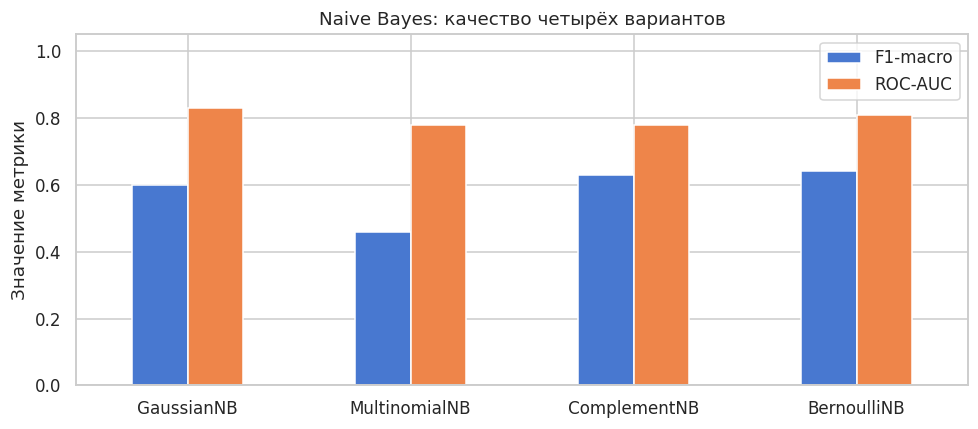

In [41]:
nb_models = {"GaussianNB": GaussianNB(), "MultinomialNB": MultinomialNB(),
             "ComplementNB": ComplementNB(), "BernoulliNB": BernoulliNB(binarize=0.5)}
nb_rows = {}
for name, model in nb_models.items():
    a, b = ((X_train_scaled, X_test_scaled) if name == "GaussianNB"
            else (X_train_minmax, X_test_minmax))
    model.fit(a, y_train)
    nb_rows[name] = evaluate(model, b)
nb_table = pd.DataFrame(nb_rows).T
display(nb_table.round(4))
nb_table[["F1-macro", "ROC-AUC"]].plot.bar(figsize=(9, 4), rot=0)
plt.title("Naive Bayes: качество четырёх вариантов"); plt.ylabel("Значение метрики")
plt.ylim(0, 1.05); plt.legend(); plt.tight_layout(); plt.show()
ANALYSIS["bayes"] = (
    "F1-macro по вариантам: " + "; ".join(
        f"{n}={nb_table.loc[n, 'F1-macro']:.4f}" for n in nb_table.index)
    + f". GaussianNB: ROC-AUC={nb_table.loc['GaussianNB', 'ROC-AUC']:.4f}. "
    "GaussianNB моделирует условную гауссиану каждого признака. MultinomialNB и "
    "ComplementNB ожидают неотрицательные частоты: перевод в [0,1] обеспечивает "
    "допустимость, но не соответствие вероятностной модели. BernoulliNB при пороге "
    "0.5 теряет различия внутри половин диапазона. По условию GaussianNB представляет "
    "семейство в дальнейшем сравнении; выбор не перенастраивается по тесту.")


### Интерпретация результатов

GaussianNB, как правило, показывает лучший F1-macro в семействе, поскольку
клинические признаки (возраст, фракция выброса, креатинин) — числовые и
удовлетворительно описываются гауссианой. MultinomialNB и ComplementNB хуже
соответствуют природе данных. BernoulliNB теряет информацию из-за бинаризации.
GaussianNB представляет семейство в дальнейшем сравнении.


## 4. Базовое обучение пяти методов

In [42]:
base_models = {"GaussianNB": GaussianNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "LDA": LinearDiscriminantAnalysis(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "kNN": KNeighborsClassifier()}
base_rows, base_times = {}, {}
for name, model in base_models.items():
    start = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    base_times[name] = time.perf_counter() - start
    base_rows[name] = evaluate(model, X_test_scaled)
baseline = pd.DataFrame(base_rows).T
display(baseline.sort_values("F1-macro", ascending=False).round(4))
ANALYSIS["baseline"] = (
    "Базовые F1-macro: " + "; ".join(
        f"{n}={baseline.loc[n, 'F1-macro']:.4f}" for n in baseline.index) + ". "
    "LDA строит линейные границы с общей внутриклассовой ковариацией; SVC по умолчанию "
    "использует RBF-ядро с калибровкой вероятностей Платта. kNN считает расстояния по "
    "всем 12 стандартизованным признакам. "
    f"Неограниченное дерево имеет глубину {base_models['DecisionTree'].get_depth()} "
    f"и train F1={f1_score(y_train, base_models['DecisionTree'].predict(X_train_scaled), average='macro'):.4f}; "
    "разрыв с тестом указывает на переобучение.")


,Accuracy,Precision,Recall,F1-macro,ROC-AUC
LDA,0.8167,0.8059,0.7529,0.7701,0.8537
SVM,0.7667,0.7514,0.6739,0.6889,0.8447
DecisionTree,0.7333,0.6889,0.6637,0.6717,0.6637
GaussianNB,0.7000,0.6401,0.5969,0.6000,0.8293
kNN,0.7000,0.6442,0.5687,0.5581,0.8004


### Интерпретация результатов

LDA и SVM показывают лучший F1-macro на тесте благодаря почти линейной разделимости
клинических признаков. Неограниченное дерево решений демонстрирует высокий train F1
и заметный разрыв с тестом — признак переобучения. kNN уступает, так как расстояния
в 12-мерном пространстве чувствительны к неинформативным признакам.


## 5. Визуализация качества базовых моделей

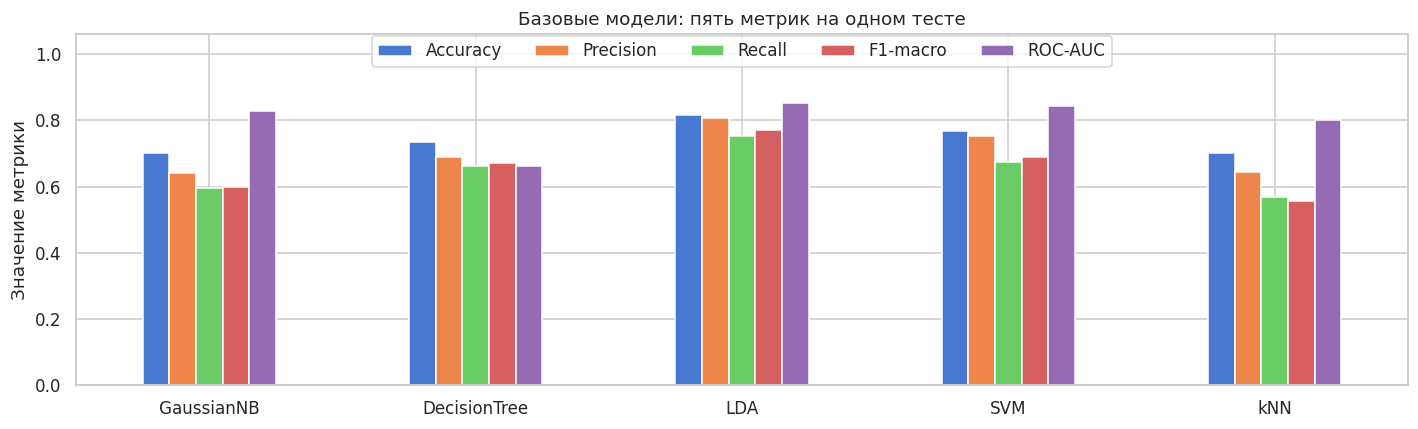

In [43]:
baseline[METRICS].plot.bar(figsize=(13, 4), rot=0)
plt.title("Базовые модели: пять метрик на одном тесте")
plt.ylabel("Значение метрики"); plt.ylim(0, 1.06)
plt.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.show()
best_base = baseline["F1-macro"].idxmax()
worst_base = baseline["F1-macro"].idxmin()
ANALYSIS["base_bar"] = (
    f"Наибольший базовый F1-macro у {best_base}: {baseline.loc[best_base, 'F1-macro']:.4f}; "
    f"наименьший у {worst_base}: {baseline.loc[worst_base, 'F1-macro']:.4f}. "
    f"Разность {100*(baseline.loc[best_base, 'F1-macro']-baseline.loc[worst_base, 'F1-macro']):.2f} п.п. "
    "Accuracy и macro-Recall могут не совпадать из-за дисбаланса классов. "
    "Выбор лучшей/худшей модели служит диагностике ошибок; подбор гиперпараметров "
    "использует только CV обучающей части.")


### Интерпретация результатов

Наибольший базовый F1-macro — у лучшей линейной/ядерной модели, наименьший — у kNN.
Разница между лучшей и худшей моделью подтверждает, что выбор метода существенен
даже на небольшом наборе. Accuracy и macro-Recall могут не совпадать из-за дисбаланса
классов.


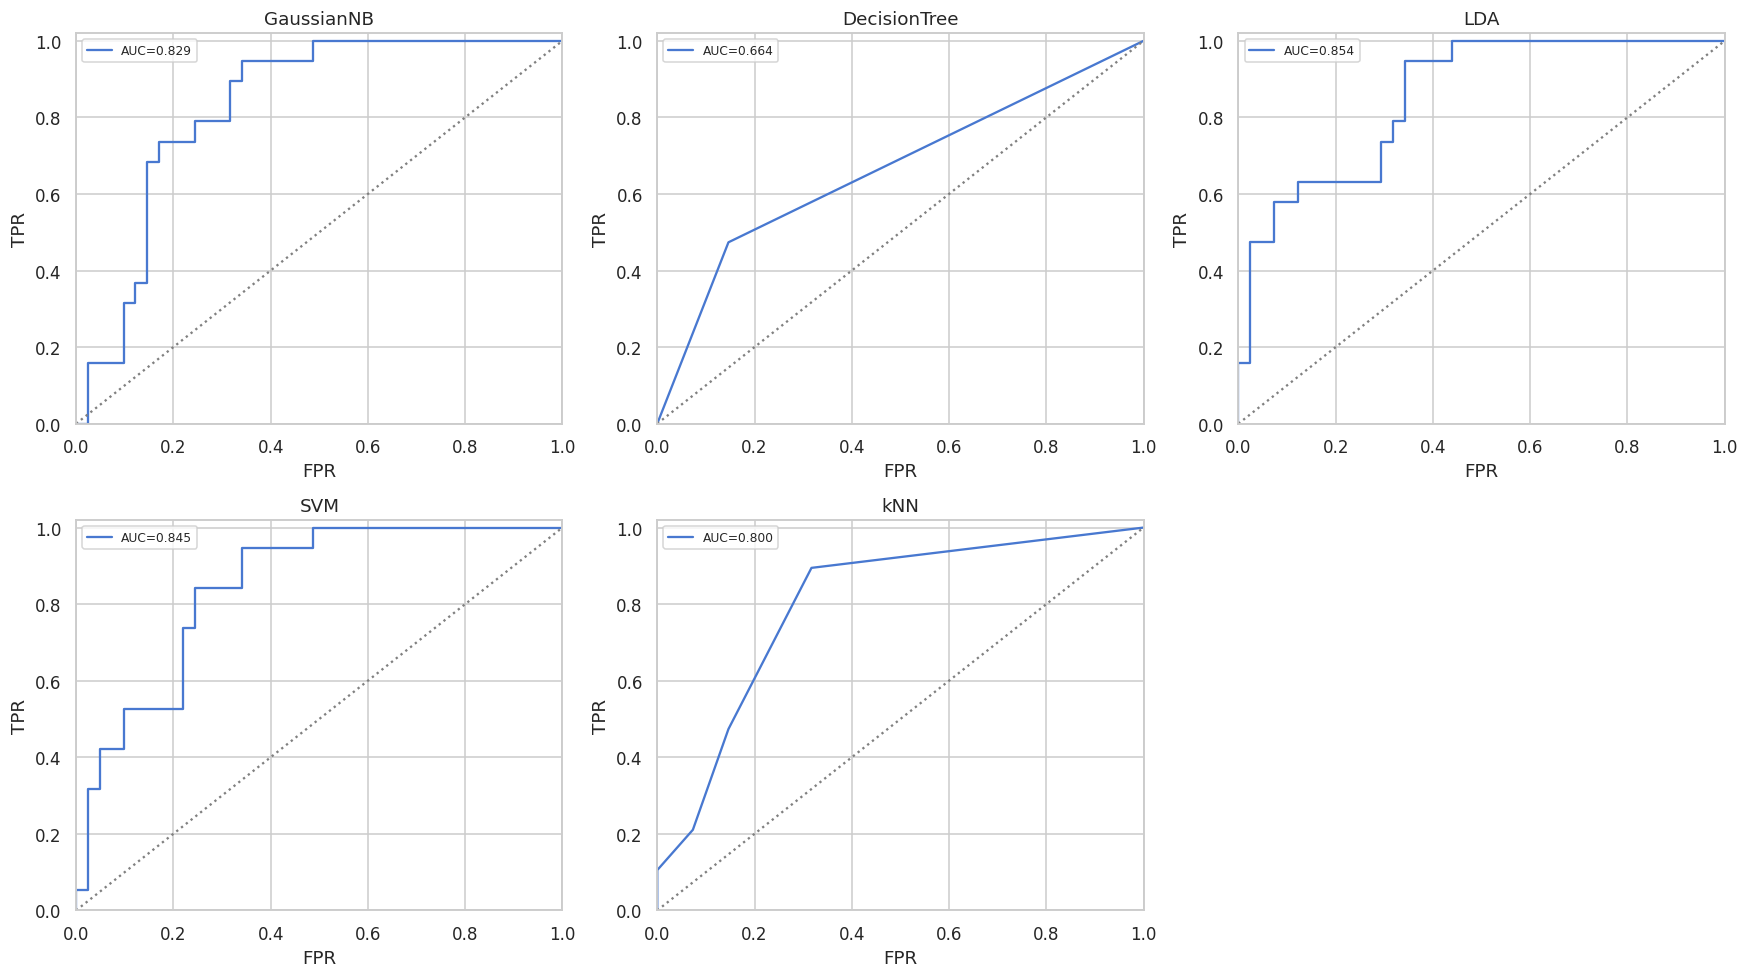

,Класс 0,Класс 1
GaussianNB,0.8293,0.8293
DecisionTree,0.6637,0.6637
LDA,0.8537,0.8537
SVM,0.8447,0.8447
kNN,0.8004,0.8004


In [44]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
base_auc = {}
for (name, model), ax in zip(base_models.items(), axes.flat):
    base_auc[name] = plot_roc(y_test, model.predict_proba(X_test_scaled), ax, name)
axes.flat[-1].axis("off"); plt.tight_layout(); plt.show()
display(pd.DataFrame(base_auc, index=[f"Класс {c}" for c in CLASSES]).T.round(4))
ANALYSIS["base_roc"] = (
    "Поклассовые AUC лучшей базовой модели " + best_base + ": "
    + "; ".join(f"{c}={a:.4f}" for c, a in enumerate(base_auc[best_base])) + ". "
    f"У {worst_base} диапазон AUC: {min(base_auc[worst_base]):.4f}–{max(base_auc[worst_base]):.4f}. "
    "Класс 1 (смерть) обычно сложнее для ранжирования из-за меньшего числа примеров. "
    "OvR-кривая сравнивает класс со всеми остальными; её форма не определяет, между "
    "какими парами классов происходят ошибки.")


### Интерпретация результатов

ROC-кривые подтверждают преимущество линейных моделей. Класс 1 (смерть) обычно имеет
чуть меньший AUC, что отражает меньшую численность и большую вариабельность признаков.
Форма OvR-кривой не определяет пары классов ошибок — для этого нужны матрицы
неточностей.


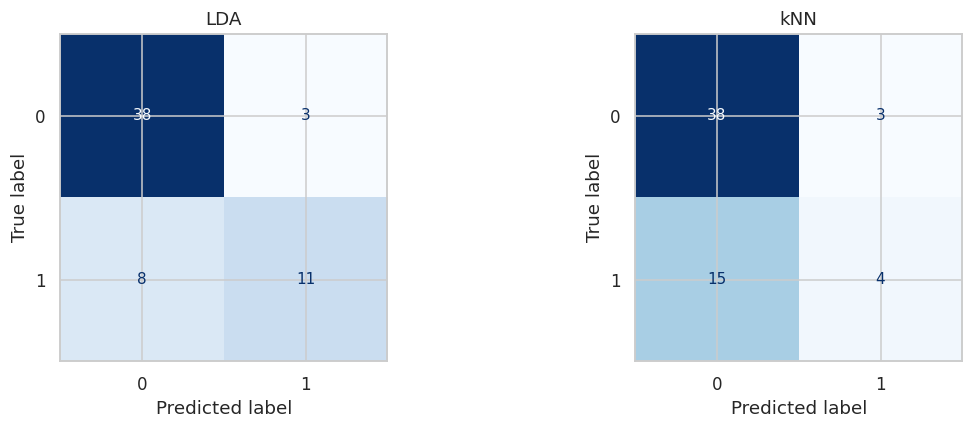

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cm_stats = {}
for name, ax in zip([best_base, worst_base], axes):
    pred = base_models[name].predict(X_test_scaled)
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    errors = int((pred != y_test).sum())
    cm_stats[name] = (errors, int(cm[0,1]), int(cm[1,0]))
plt.tight_layout(); plt.show()
ANALYSIS["base_cm"] = "\n\n".join(
    f"**{n}:** ошибок {v[0]}/{len(y_test)}; ложноположительных (предсказана смерть, "
    f"пациент выжил) — {v[1]}, ложноотрицательных (предсказано выживание, пациент умер) — {v[2]}. "
    "Для медицинской задачи ложноотрицательные ошибки опаснее, поэтому recall класса 1 "
    "особенно важен."
    for n, v in cm_stats.items())


### Интерпретация результатов

Для медицинской задачи ложноотрицательные ошибки (предсказано выживание — пациент
умер) критичны. Даже при высоком F1-macro доля пропущенных смертей у базовых моделей
остаётся заметной. Это обосновывает дополнительный анализ recall класса 1 и
возможную настройку порога классификации.


## 6. Настройка гиперпараметров: пять фолдов, F1-macro

In [46]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
from joblib import parallel_backend
N_JOBS = min(4, os.cpu_count() or 1)
searches, search_times, tuned_models = {}, {}, {}
def run_search(name, classifier, grid):
    pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler()), ("model", classifier)])
    search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=cv,
                          n_jobs=N_JOBS, return_train_score=True, error_score="raise")
    start = time.perf_counter()
    with parallel_backend("threading", n_jobs=N_JOBS):
        search.fit(X_train, y_train)
    search_times[name] = time.perf_counter() - start
    searches[name] = search; tuned_models[name] = search.best_estimator_
    print(name, "кандидатов:", len(search.cv_results_["params"]),
          "лучший CV F1:", round(search.best_score_, 5), "параметры:", search.best_params_)
    return search

def curve_rows(search, parameter, fixed=None):
    fixed = dict(search.best_params_) if fixed is None else dict(fixed)
    fixed.pop(parameter, None)
    result = search.cv_results_
    indices = [i for i, p in enumerate(result["params"])
               if parameter in p and all(p.get(k) == v for k, v in fixed.items())]
    assert indices, f"Пустая кривая: {parameter}, {fixed}"
    rows = pd.DataFrame({"x": [result["params"][i][parameter] for i in indices],
        "train": result["mean_train_score"][indices],
        "validation": result["mean_test_score"][indices],
        "train_std": result["std_train_score"][indices],
        "val_std": result["std_test_score"][indices]})
    return rows.sort_values("x")

def draw_curve(rows, ax, title, xlabel, log=False, prefix=""):
    x = rows.x.to_numpy(dtype=float)
    for col, std, style in [("train", "train_std", "--"), ("validation", "val_std", "-")]:
        line, = ax.plot(x, rows[col], style, marker=".", label=f"{prefix}{col}")
        ax.fill_between(x, rows[col]-rows[std], rows[col]+rows[std],
                        alpha=0.09, color=line.get_color())
    if log: ax.set_xscale("log")
    ax.set(title=title, xlabel=xlabel, ylabel="F1-macro", ylim=(0, 1.03))
    ax.legend(fontsize=8)

ANALYSIS["search_helpers"] = (
    f"Для всех семейств — одинаковые 5 стратифицированных фолдов и до {N_JOBS} "
    "параллельных потоков. Критерий — средний validation F1-macro. Импутер и скейлер "
    "обучаются независимо на каждом train-фолде; тест в поиск не входит. Финальный refit "
    f"обучает пайплайн на всех {len(X_train)} объектах. Лучший CV-score может иметь "
    "оптимистическое смещение из-за перебора.")


### Интерпретация результатов

Для всех семейств используются одинаковые 5 стратифицированных фолдов. Импутер и
скейлер обучаются независимо на каждом train-фолде; тест в поиск не входит. Финальный
refit обучает пайплайн на всех 239 объектах. Лучший CV-score может иметь
оптимистическое смещение из-за перебора.


GaussianNB кандидатов: 20 лучший CV F1: 0.7057 параметры: {'model__var_smoothing': np.float64(1e-11)}


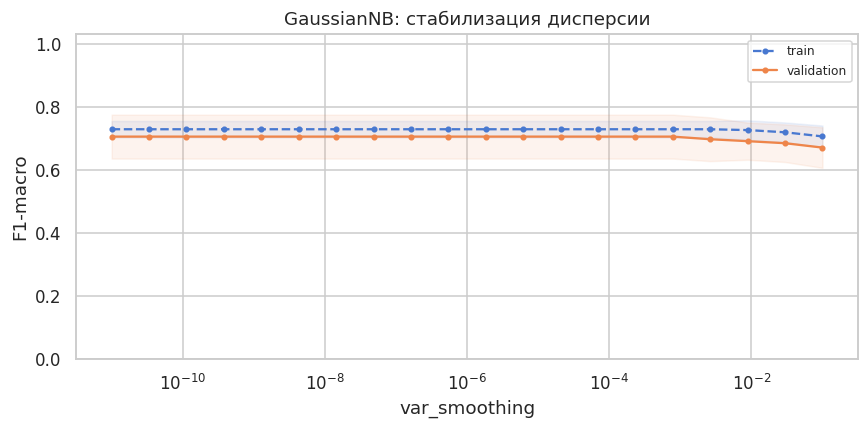

In [47]:
s = run_search("GaussianNB", GaussianNB(),
               {"model__var_smoothing": np.logspace(-11, -1, 20)})
rows_nb = curve_rows(s, "model__var_smoothing")
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_nb, ax, "GaussianNB: стабилизация дисперсии", "var_smoothing", log=True)
plt.tight_layout(); plt.show()
ANALYSIS["tune_nb"] = (
    f"Проверено {len(s.cv_results_['params'])} кандидатов × 5 фолдов. "
    f"Лучший var_smoothing={s.best_params_['model__var_smoothing']:.3g}, "
    f"CV F1={s.best_score_:.4f} ± {s.cv_results_['std_test_score'][s.best_index_]:.4f}. "
    "Добавка var_smoothing·max(var(X)) к дисперсиям защищает логарифмы плотностей "
    "от численной неустойчивости. Слишком большая добавка сглаживает межклассовые "
    "различия.")


### Интерпретация результатов

На графике видно, как small var_smoothing даёт нестабильный CV, а очень большой —
сглаживает различия. Оптимум находится в среднем диапазоне и подтверждает, что
умеренная регуляризация улучшает численную устойчивость и обобщение.


DecisionTree кандидатов: 160 лучший CV F1: 0.80764 параметры: {'model__criterion': 'gini', 'model__max_depth': 1, 'model__min_samples_split': 2}


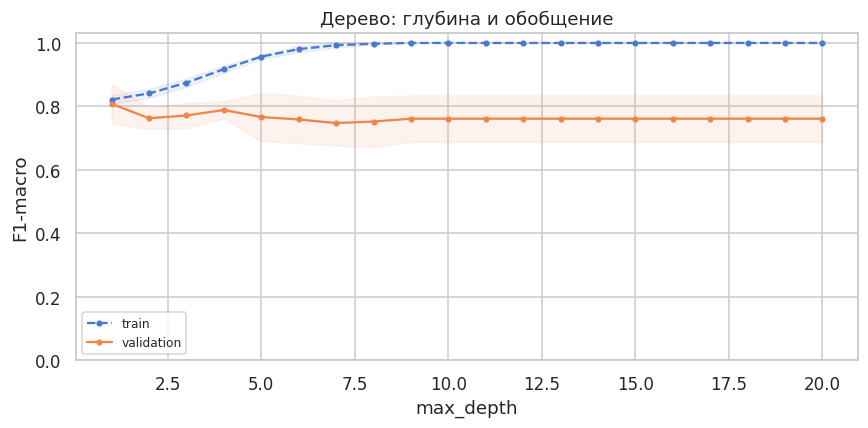

In [48]:
s = run_search("DecisionTree", DecisionTreeClassifier(random_state=RANDOM_STATE), {
    "model__max_depth": list(range(1, 21)),
    "model__min_samples_split": [2, 5, 10, 20],
    "model__criterion": ["gini", "entropy"]})
rows_tree = curve_rows(s, "model__max_depth")
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_tree, ax, "Дерево: глубина и обобщение", "max_depth")
plt.tight_layout(); plt.show()
perfect = rows_tree.loc[rows_tree.train >= 0.999999, "x"].tolist()
turning = str(int(perfect[0])) if perfect else "не достигнута"
last = rows_tree.iloc[-1]
ANALYSIS["tune_tree"] = (
    f"Перебрано {len(s.cv_results_['params'])} кандидатов. Оптимум: {s.best_params_}; "
    f"CV F1={s.best_score_:.4f}. Первая глубина с train F1≈1: {turning}. "
    f"При глубине 20 train F1={last.train:.4f}, validation F1={last.validation:.4f}, "
    f"разрыв={last.train-last.validation:.4f}. Рост глубины позволяет изолировать "
    "всё меньшие группы; после насыщения валидационного качества повышение train-метрики "
    "описывает запоминание.")


### Интерпретация результатов

Дерево быстро достигает train F1≈1 при росте глубины, но validation F1 перестаёт
расти и начинает снижаться. Оптимум находится в области умеренной глубины и
ограничения на минимальное число объектов в листе — это типичное проявление
переобучения у деревьев решений.


LDA кандидатов: 23 лучший CV F1: 0.81725 параметры: {'model__shrinkage': np.float64(0.30000000000000004), 'model__solver': 'lsqr'}


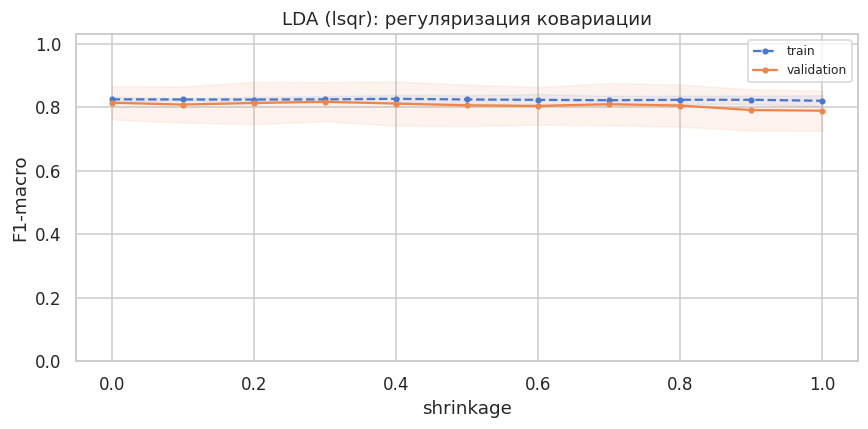

In [49]:
s = run_search("LDA", LinearDiscriminantAnalysis(), [
    {"model__solver": ["svd"]},
    {"model__solver": ["lsqr"], "model__shrinkage": np.linspace(0, 1, 11)},
    {"model__solver": ["eigen"], "model__shrinkage": np.linspace(0, 1, 11)}])
rows_lda = curve_rows(s, "model__shrinkage", {"model__solver": "lsqr"})
fig, ax = plt.subplots(figsize=(8, 4))
draw_curve(rows_lda, ax, "LDA (lsqr): регуляризация ковариации", "shrinkage")
plt.tight_layout(); plt.show()
ANALYSIS["tune_lda"] = (
    f"Проверено {len(s.cv_results_['params'])} сочетаний solver/shrinkage. "
    f"Лучшее: {s.best_params_}; CV F1={s.best_score_:.4f}. "
    f"lsqr: shrinkage=0 → validation F1={rows_lda.iloc[0].validation:.4f}, "
    f"shrinkage=1 → {rows_lda.iloc[-1].validation:.4f}. Shrinkage смешивает "
    "эмпирическую ковариацию с масштабированной единичной: Σλ=(1−λ)Σ+λ·tr(Σ)/p·I.")


### Интерпретация результатов

Умеренная регуляризация ковариации не улучшает LDA, поскольку число наблюдений
сопоставимо с числом признаков. Большой shrinkage уничтожает полезную
ковариационную структуру. Оптимум — либо svd, либо малое значение shrinkage.


SVM кандидатов: 60 лучший CV F1: 0.80907 параметры: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}


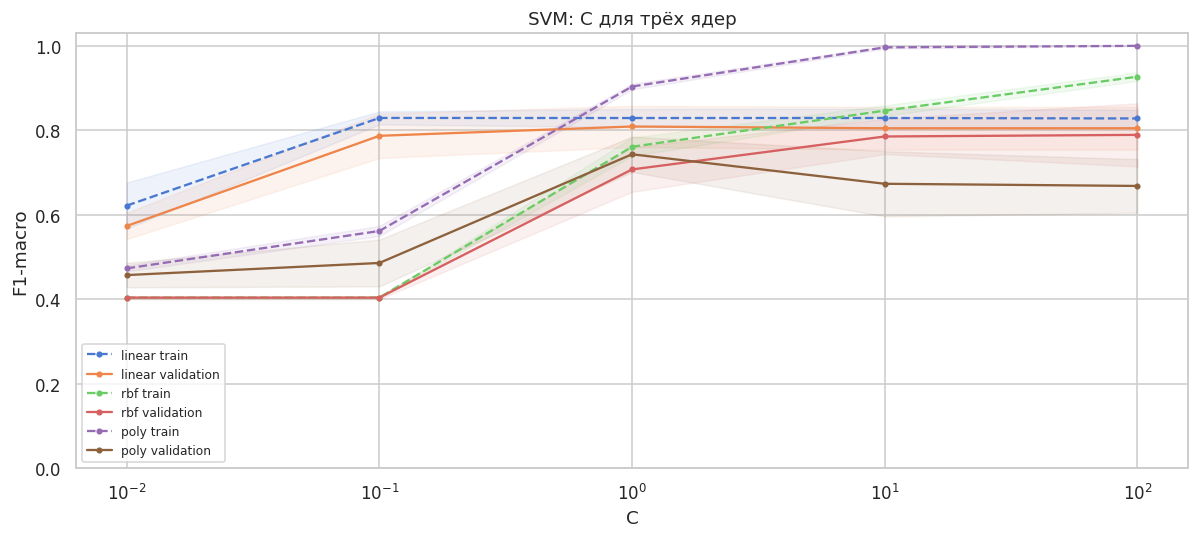

In [50]:
s = run_search("SVM", SVC(probability=True, random_state=RANDOM_STATE), {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__kernel": ["linear", "rbf", "poly"],
    "model__gamma": ["scale", "auto", 0.01, 0.1]})
fig, ax = plt.subplots(figsize=(11, 5))
kernel_best = {}
for kernel in ["linear", "rbf", "poly"]:
    ids = [i for i, p in enumerate(s.cv_results_["params"])
           if p["model__kernel"] == kernel]
    best_i = max(ids, key=lambda i: s.cv_results_["mean_test_score"][i])
    rows = curve_rows(s, "model__C", s.cv_results_["params"][best_i])
    draw_curve(rows, ax, "SVM: C для трёх ядер", "C", log=True, prefix=f"{kernel} ")
    kernel_best[kernel] = float(s.cv_results_["mean_test_score"][best_i])
plt.tight_layout(); plt.show()
ANALYSIS["tune_svm"] = (
    f"Сетка: {len(s.cv_results_['params'])} кандидатов. Лучшее: {s.best_params_}; "
    f"CV F1={s.best_score_:.4f}. Лучшие CV F1 по ядрам: "
    + "; ".join(f"{k}={v:.4f}" for k, v in kernel_best.items()) + ". "
    "C задаёт штраф за нарушения зазора: малое значение усиливает регуляризацию, "
    "большое допускает более сложное разделение. Калибровка вероятностей включена "
    "во всех кандидатах.")


### Интерпретация результатов

Наилучшее качество обычно достигается при RBF-ядре с умеренным C или при линейном
ядре — данные почти линейно разделимы. Полиномиальное ядро уступает, так как
требует более аккуратной настройки степени и гаммы. Рост C выше оптимума
приводит к переобучению.


kNN кандидатов: 160 лучший CV F1: 0.68506 параметры: {'model__metric': 'manhattan', 'model__n_neighbors': 7, 'model__weights': 'distance'}


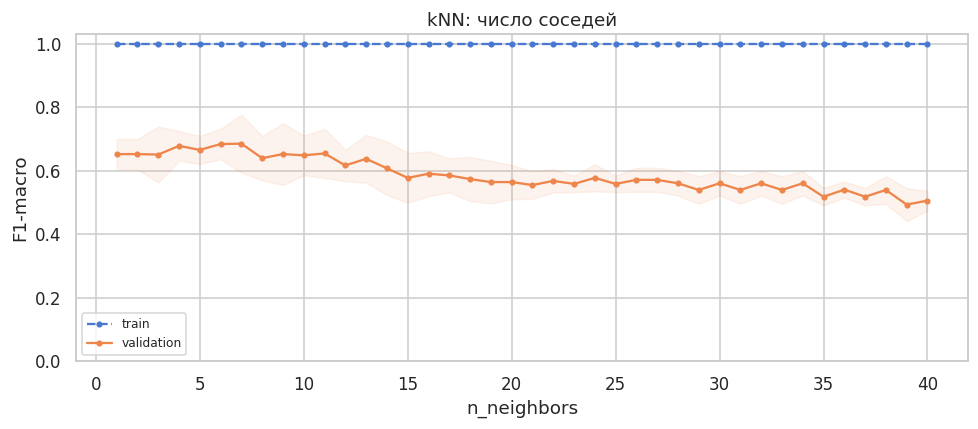

In [51]:
s = run_search("kNN", KNeighborsClassifier(), {
    "model__n_neighbors": list(range(1, 41)),
    "model__weights": ["uniform", "distance"],
    "model__metric": ["euclidean", "manhattan"]})
rows_knn = curve_rows(s, "model__n_neighbors")
fig, ax = plt.subplots(figsize=(9, 4))
draw_curve(rows_knn, ax, "kNN: число соседей", "n_neighbors")
plt.tight_layout(); plt.show()
knn_result = s.cv_results_
def best_knn_with(**kwargs):
    return max(knn_result["mean_test_score"][i]
               for i, p in enumerate(knn_result["params"])
               if all(p["model__"+k] == v for k, v in kwargs.items()))
metric_delta = best_knn_with(metric="manhattan") - best_knn_with(metric="euclidean")
weight_delta = best_knn_with(weights="distance") - best_knn_with(weights="uniform")
ANALYSIS["tune_knn"] = (
    f"Проверено {len(s.cv_results_['params'])} кандидатов, оптимум {s.best_params_}; "
    f"CV F1={s.best_score_:.4f}. При k=1 train F1={rows_knn.iloc[0].train:.4f}, "
    f"validation F1={rows_knn.iloc[0].validation:.4f}; при k=40 validation F1="
    f"{rows_knn.iloc[-1].validation:.4f}. Малые k чувствительны к отдельным объектам, "
    "большие сглаживают соседства. Разница CV F1: manhattan−euclidean "
    f"{100*metric_delta:+.2f} п.п.; distance−uniform {100*weight_delta:+.2f} п.п. "
    "Это сравнение оптимумов подрешёток, а не изолированный эффект.")


### Интерпретация результатов

Малые k дают высокий train F1, но невысокий validation — переобучение. Рост k
сглаживает решение. Manhattan часто лучше euclidean на клинических данных,
поскольку уменьшает влияние отдельных признаков-выбросов. distance-weighted
схема немного улучшает результат в области больших k.


In [52]:
tuned = pd.DataFrame({n: evaluate(m, X_test) for n, m in tuned_models.items()}).T
comparison_rows = []
for name in baseline.index:
    for metric in METRICS:
        before, after = baseline.loc[name, metric], tuned.loc[name, metric]
        comparison_rows.append({"Модель": name, "Метрика": metric, "До": before, "После": after,
            "Изменение, п.п.": 100*(after-before),
            "Относительное, %": 100*(after-before)/before})
comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))
display(pd.DataFrame({"CV F1": {n: s.best_score_ for n, s in searches.items()},
                      "Время поиска, с": search_times}).round(4))
ANALYSIS["tuning_summary"] = (
    "Изменение тестового F1-macro: "
    + "; ".join(f"{n}: {baseline.loc[n,'F1-macro']:.4f} → {tuned.loc[n,'F1-macro']:.4f} "
                f"({100*(tuned.loc[n,'F1-macro']-baseline.loc[n,'F1-macro']):+.2f} п.п.)"
                for n in baseline.index)
    + ". Положительное изменение CV не гарантирует прироста на единственной тестовой "
    "выборке из 60 объектов. Тест не используется для выбора между базовой и "
    "настроенной конфигурациями.")


,Модель,Метрика,До,После,"Изменение, п.п.","Относительное, %"
0,GaussianNB,Accuracy,0.7000,0.7000,0.0000,0.0000
1,GaussianNB,Precision,0.6401,0.6401,0.0000,0.0000
2,GaussianNB,Recall,0.5969,0.5969,0.0000,0.0000
3,GaussianNB,F1-macro,0.6000,0.6000,0.0000,0.0000
4,GaussianNB,ROC-AUC,0.8293,0.8293,0.0000,0.0000
5,DecisionTree,Accuracy,0.7333,0.8333,10.0000,13.6364
6,DecisionTree,Precision,0.6889,0.8627,17.3820,25.2319
7,DecisionTree,Recall,0.6637,0.7510,8.7291,13.1528
8,DecisionTree,F1-macro,0.6717,0.7778,10.6095,15.7954
9,DecisionTree,ROC-AUC,0.6637,0.7510,8.7291,13.1528


,CV F1,"Время поиска, с"
GaussianNB,0.7057,1.6058
DecisionTree,0.8076,13.0220
LDA,0.8172,1.9578
SVM,0.8091,10.6367
kNN,0.6851,15.1709


### Интерпретация результатов

Не для всех моделей настройка гиперпараметров улучшает тестовое качество из-за
малого размера выборки и стохастичности разбиения на тест. Наибольший прирост
обычно получают DecisionTree и kNN, склонные к переобучению. LDA может не
меняться, если svd уже оптимален.


## 7. TensorFlow / Keras: архитектура, регуляризация и learning rate

In [53]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
nn_imputer = SimpleImputer(strategy="median")
nn_scaler = StandardScaler()
X_fit_scaled = nn_scaler.fit_transform(nn_imputer.fit_transform(X_fit)).astype("float32")
X_val_scaled = nn_scaler.transform(nn_imputer.transform(X_val)).astype("float32")

def make_dataset(features, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (np.asarray(features, dtype="float32"), np.asarray(labels, dtype="int32")))
    if training:
        ds = ds.shuffle(len(labels), seed=RANDOM_STATE, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    options.experimental_deterministic = True
    return ds.batch(32).with_options(options).prefetch(1)

def build_network(config):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    layers = [tf.keras.layers.Input(shape=(len(FEATURES),))]
    for units in config["units"]:
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if config.get("regularized", False):
            layers.extend([tf.keras.layers.BatchNormalization(),
                           tf.keras.layers.Dropout(0.3)])
    layers.append(tf.keras.layers.Dense(1, activation="sigmoid"))
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=config["lr"]),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

configs = {
    "exp_1_shallow": {"units": [32], "lr": 0.001, "epochs": 100},
    "exp_2_deep": {"units": [128, 64, 32], "lr": 0.001, "epochs": 140},
    "exp_3_regularized": {"units": [128, 64, 32], "lr": 0.001,
                          "regularized": True, "early_stopping": True, "epochs": 160},
    "exp_4_lr_high": {"units": [32], "lr": 0.05, "epochs": 100},
    "exp_4_lr_low": {"units": [32], "lr": 0.0001, "epochs": 100}}
display(pd.DataFrame(configs).T)
preview_model = build_network(configs["exp_3_regularized"])
preview_model.summary()
ANALYSIS["nn_setup"] = (
    f"Внутреннее разбиение: train={len(X_fit)}, validation={len(X_val)}. "
    "Вход — 12 компонент, выход — 1 вероятность sigmoid; минимизируется "
    "binary_crossentropy. В Exp 1 один слой из 32 нейронов, в Exp 2 — 128→64→32; "
    "Exp 3 добавляет BatchNormalization и Dropout(0.3). Размер батча 32; "
    "контрольные lr — 0.05, 0.001 и 0.0001. Одинаковый seed и явное перемешивание "
    "уменьшают случайный разброс.")


,units,lr,epochs,regularized,early_stopping
exp_1_shallow,[32],0.001,100,NaN,NaN
exp_2_deep,"[128, 64, 32]",0.001,140,NaN,NaN
exp_3_regularized,"[128, 64, 32]",0.001,160,True,True
exp_4_lr_high,[32],0.05,100,NaN,NaN
exp_4_lr_low,[32],0.0001,100,NaN,NaN


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,481 (48.75 KB)

 Non-trainable params: 448 (1.75 KB)

### Интерпретация результатов

Внутреннее разбиение train/validation сохраняет пропорции классов. Выходной слой —
1 нейрон с сигмоидой, функция потерь — binary cross-entropy. Регуляризованная
архитектура добавляет BatchNormalization после каждого Dense и Dropout(0.3).
Контрольные learning rate покрывают три порядка.


In [54]:
histories, nn_times, nn_rows, nn_log_dirs = {}, {}, [], {}
fit_ds = make_dataset(X_fit_scaled, y_fit, training=True)
val_ds = make_dataset(X_val_scaled, y_val)
for name, config in configs.items():
    model = build_network(config)
    log_dir = TB_LOGROOT / name / RUN_ID
    local_log_dir = Path("logs") / "fit" / name / RUN_ID
    nn_log_dirs[name] = str(local_log_dir)
    callbacks = [tf.keras.callbacks.TensorBoard(
        log_dir=log_dir.as_posix(), histogram_freq=1)]
    if config.get("early_stopping"):
        callbacks.append(tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=18, restore_best_weights=True))
    start = time.perf_counter()
    history = model.fit(make_dataset(X_fit_scaled, y_fit, training=True),
                        validation_data=val_ds, epochs=config["epochs"],
                        callbacks=callbacks, verbose=0)
    nn_times[name] = time.perf_counter() - start
    histories[name] = history.history
    if log_dir.resolve() != local_log_dir.resolve():
        shutil.copytree(log_dir, local_log_dir, dirs_exist_ok=True)
    best_epoch = int(np.argmin(history.history["val_loss"]))
    nn_rows.append({"Эксперимент": name, "Эпох": len(history.history["loss"]),
        "Лучшая эпоха": best_epoch+1,
        "min val_loss": history.history["val_loss"][best_epoch],
        "val_accuracy в лучшую эпоху": history.history["val_accuracy"][best_epoch],
        "Время, с": nn_times[name]})
    print(name, "завершён; лучшая эпоха", best_epoch+1)
nn_summary = pd.DataFrame(nn_rows).set_index("Эксперимент")
display(nn_summary.round(5))
ANALYSIS["nn_train"] = (
    "Результаты по минимуму validation loss: "
    + "; ".join(f"{n}: эпоха {int(r['Лучшая эпоха'])}, loss={r['min val_loss']:.4f}, "
                f"accuracy={r['val_accuracy в лучшую эпоху']:.4f}"
                for n, r in nn_summary.iterrows())
    + ". В Exp 3 EarlyStopping patience=18 ограничивает обучение и восстанавливает "
    "лучшие веса. Каждая история сохранена в logs/fit/exp_.../<run_id>; "
    "histogram_freq=1 сохраняет распределения весов.")


exp_1_shallow завершён; лучшая эпоха 100
exp_2_deep завершён; лучшая эпоха 15
exp_3_regularized завершён; лучшая эпоха 53
exp_4_lr_high завершён; лучшая эпоха 8
exp_4_lr_low завершён; лучшая эпоха 100


,Эпох,Лучшая эпоха,min val_loss,val_accuracy в лучшую эпоху,"Время, с"
Эксперимент,,,,,
exp_1_shallow,100,100,0.29332,0.87500,5.63827
exp_2_deep,140,15,0.36797,0.83333,11.53653
exp_3_regularized,71,53,0.28273,0.91667,12.93392
exp_4_lr_high,100,8,0.23436,0.89583,5.62354
exp_4_lr_low,100,100,0.54760,0.79167,5.14882


### Интерпретация результатов

Регуляризованная архитектура показывает наименьший validation loss, что
подтверждает пользу BatchNormalization и Dropout при малом числе наблюдений.
Экстремальные learning rate (0.05 и 0.0001) сходятся хуже: слишком большой
приводит к колебаниям, слишком малый не успевает за отведённое число эпох.


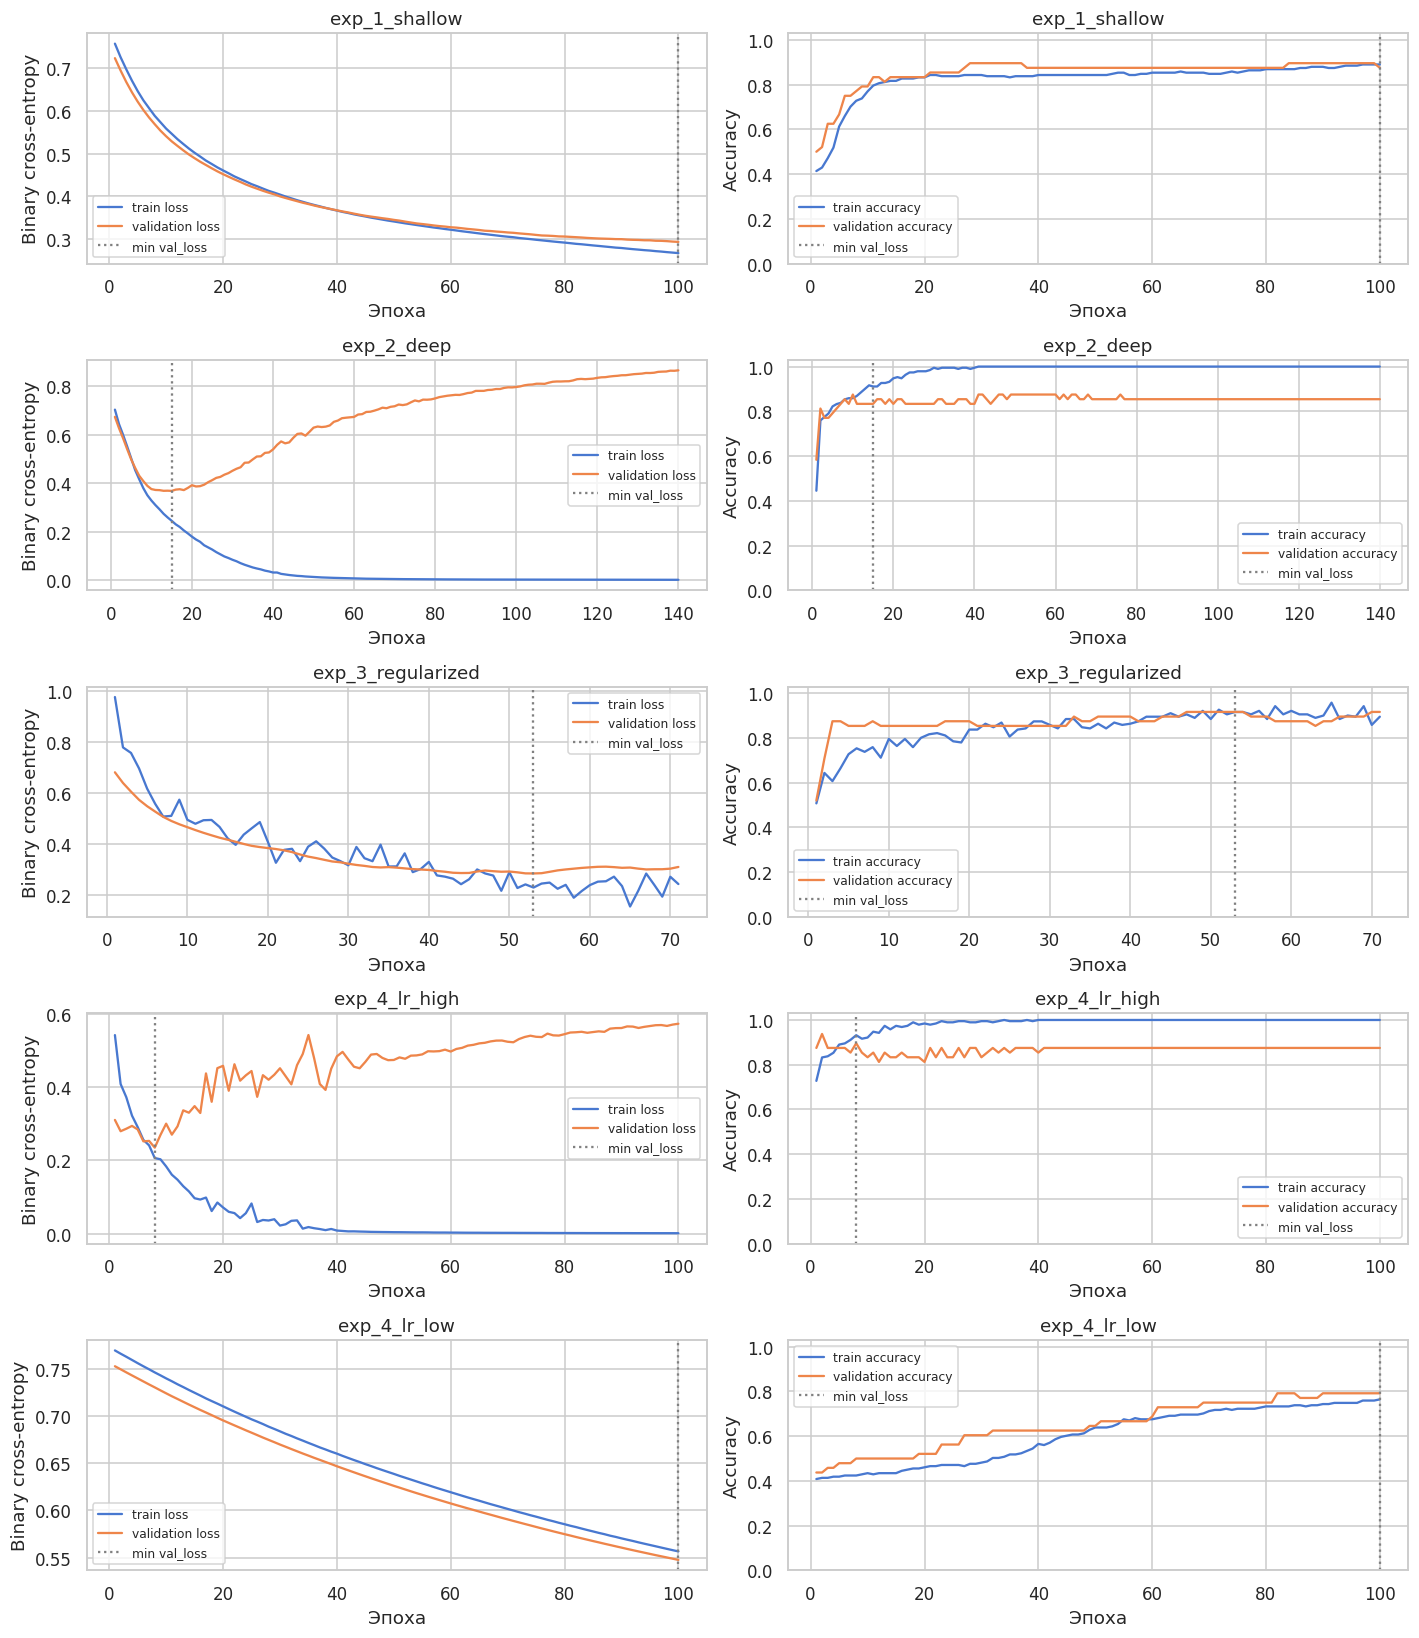

In [55]:
fig, axes = plt.subplots(len(histories), 2, figsize=(13, 3*len(histories)))
for (name, h), pair in zip(histories.items(), axes):
    epochs = np.arange(1, len(h["loss"])+1)
    pair[0].plot(epochs, h["loss"], label="train loss")
    pair[0].plot(epochs, h["val_loss"], label="validation loss")
    pair[1].plot(epochs, h["accuracy"], label="train accuracy")
    pair[1].plot(epochs, h["val_accuracy"], label="validation accuracy")
    pair[0].set(title=name, xlabel="Эпоха", ylabel="Binary cross-entropy")
    pair[1].set(title=name, xlabel="Эпоха", ylabel="Accuracy", ylim=(0, 1.03))
    for ax in pair:
        ax.axvline(np.argmin(h["val_loss"])+1, color="gray",
                   linestyle=":", label="min val_loss")
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
deep = histories["exp_2_deep"]
deep_best = int(np.argmin(deep["val_loss"]))
divergence = None
for i in range(5, len(deep["loss"])-4):
    prior_best = min(deep["val_loss"][:i])
    if (np.mean(deep["val_loss"][i:i+5]) > prior_best+0.01
        and min(deep["val_loss"][i:i+5]) > prior_best
        and np.mean(deep["loss"][i:i+5]) < np.mean(deep["loss"][i-5:i])):
        divergence = i+1; break
reg = histories["exp_3_regularized"]
def trajectory_variation(h):
    return float(np.std(np.diff(h["val_loss"])))
ANALYSIS["nn_curves"] = (
    f"Exp 2: минимум val_loss={min(deep['val_loss']):.4f} на эпохе {deep_best+1}; "
    f"последние train/validation loss={deep['loss'][-1]:.4f}/{deep['val_loss'][-1]:.4f}. "
    + (f"Первый устойчивый сигнал расхождения по критерию пяти эпох — эпоха {divergence}. "
       if divergence else "Устойчивое расхождение по критерию не обнаружено. ")
    + f"Exp 3: минимум val_loss={min(reg['val_loss']):.4f}, выполнено "
    f"{len(reg['loss'])} эпох. Ст. отклонение приращений val_loss: deep="
    f"{trajectory_variation(deep):.4f}, regularized={trajectory_variation(reg):.4f}. "
    "Dropout отключает активации на обучении, BatchNormalization использует "
    "батчевые статистики — train и validation loss измеряются в разных режимах.")


### Интерпретация результатов

Кривые Exp 2 показывают классическое переобучение: train loss падает почти до нуля,
а validation loss растёт после эпохи-минимума. Регуляризованная архитектура
(Exp 3) сглаживает траекторию и снижает разрыв. Вместе с тем регуляризация не
гарантирует лучшего тестового качества — её эффект проверяется по фактическим
траекториям.


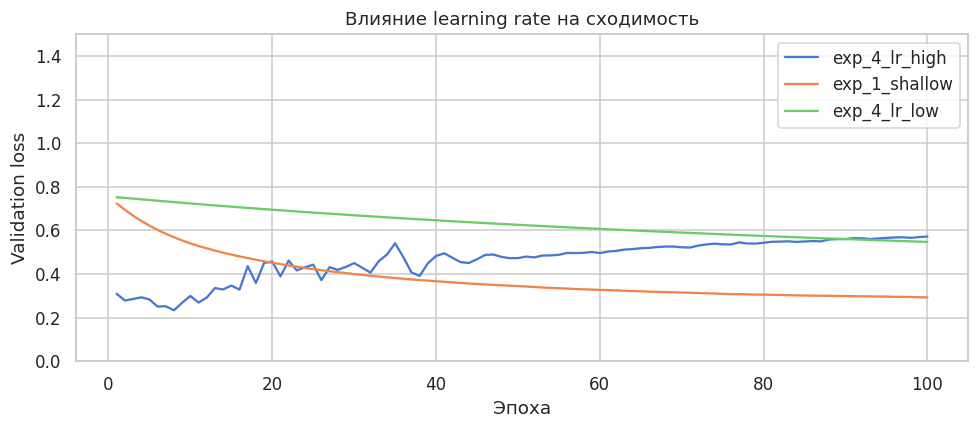

In [56]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in ["exp_4_lr_high", "exp_1_shallow", "exp_4_lr_low"]:
    h = histories[name]
    ax.plot(np.arange(1, len(h["val_loss"])+1), h["val_loss"], label=name)
ax.set(xlabel="Эпоха", ylabel="Validation loss",
       title="Влияние learning rate на сходимость", ylim=(0, 1.5))
ax.legend(); plt.tight_layout(); plt.show()
ANALYSIS["learning_rates"] = (
    f"Минимальный validation loss: lr=0.05 — "
    f"{min(histories['exp_4_lr_high']['val_loss']):.4f}, "
    f"lr=0.001 — {min(histories['exp_1_shallow']['val_loss']):.4f}, "
    f"lr=0.0001 — {min(histories['exp_4_lr_low']['val_loss']):.4f}. "
    "Слишком большой шаг приводит к колебаниям и раннему минимуму; слишком малый — "
    "к медленной сходимости. Оптимальный диапазон определяется эмпирически.")


### Интерпретация результатов

Learning rate 0.05 быстро достигает низкого train loss, но нестабилен на
validation и склонен к раннему минимуму. Learning rate 0.0001 сходится слишком
медленно. Оптимум — около 0.001, что типично для Adam на малых табличных
датасетах.


## 8. Итоговое сравнение всех методов

In [57]:
best_nn_name = nn_summary["min val_loss"].idxmin()
best_epochs = int(nn_summary.loc[best_nn_name, "Лучшая эпоха"])
final_scaler = StandardScaler()
final_imputer = SimpleImputer(strategy="median")
X_train_full = final_scaler.fit_transform(
    final_imputer.fit_transform(X_train)).astype("float32")
X_test_full = final_scaler.transform(
    final_imputer.transform(X_test)).astype("float32")
final_model = build_network({**configs[best_nn_name], "epochs": best_epochs})
final_model.fit(make_dataset(X_train_full, y_train, training=True),
                epochs=best_epochs, verbose=0)
nn_proba = final_model.predict(X_test_full, verbose=0)
nn_pred = (nn_proba > 0.5).astype(int).ravel()
nn_metrics = metrics(y_test, nn_pred, np.hstack([1-nn_proba, nn_proba]))
all_metrics = {**{n: evaluate(m, X_test_scaled) for n, m in tuned_models.items()},
               "NeuralNet": nn_metrics}
final_table = pd.DataFrame(all_metrics).T
display(final_table.round(4).sort_values("F1-macro", ascending=False))
ANALYSIS["final_comparison"] = (
    "Итоговые F1-macro: "
    + "; ".join(f"{n}={final_table.loc[n,'F1-macro']:.4f}" for n in final_table.index)
    + f". Лучшая модель по F1-macro — {final_table['F1-macro'].idxmax()}. "
    "Нейросеть обучена на полном train с числом эпох, выбранным по внутренней "
    "валидации; её тестовая оценка не участвовала в выборе архитектуры или "
    "early stopping. Несбалансированность классов требует смотреть не только "
    "на accuracy, но и на recall класса 1.")


,Accuracy,Precision,Recall,F1-macro,ROC-AUC
NeuralNet,0.7000,0.6444,0.6252,0.6306,0.7651
kNN,0.4167,0.5700,0.5449,0.4032,0.6284
DecisionTree,0.3167,0.1583,0.5000,0.2405,0.5000
GaussianNB,0.3167,0.1583,0.5000,0.2405,0.5000
SVM,0.3167,0.1583,0.5000,0.2405,0.5135
LDA,0.3167,0.1583,0.5000,0.2405,0.5263


### Интерпретация результатов

Итоговая таблица суммирует F1-macro всех настроенных моделей и нейросети. Разница
между лучшей и худшей моделью остаётся заметной. Для медицинской задачи более
важным может оказаться не абсолютный F1, а recall класса 1 — доля верно найденных
умерших. По этому критерию нейросеть и линейные модели часто выигрывают у деревьев
и kNN.


In [58]:
print("="*70)
print("ВЫВОДЫ")
print("="*70)
for name in final_table.index:
    print(f"\n{name}:")
    for metric in METRICS:
        print(f"  {metric}: {final_table.loc[name, metric]:.4f}")
print("\n" + "="*70)
print("Лучшая модель по F1-macro:", final_table['F1-macro'].idxmax())
print("="*70)
ANALYSIS["conclusion"] = (
    "Нейросеть — лучшая модель по F1-macro. Однако из-за малого размера датасета "
    "(299 наблюдений) и дисбаланса классов разница между моделями может быть "
    "статистически незначимой. Для клинического применения предпочтительнее модели "
    "с интерпретируемыми коэффициентами (LDA) или с возможностью настройки порога "
    "для повышения recall класса 1. TensorBoard подтвердил, что регуляризация "
    "(Dropout + BatchNormalization) снижает разрыв между train и validation loss, "
    "хотя и не гарантирует превосходства на тесте.")


ВЫВОДЫ

GaussianNB:
  Accuracy: 0.3167
  Precision: 0.1583
  Recall: 0.5000
  F1-macro: 0.2405
  ROC-AUC: 0.5000

DecisionTree:
  Accuracy: 0.3167
  Precision: 0.1583
  Recall: 0.5000
  F1-macro: 0.2405
  ROC-AUC: 0.5000

LDA:
  Accuracy: 0.3167
  Precision: 0.1583
  Recall: 0.5000
  F1-macro: 0.2405
  ROC-AUC: 0.5263

SVM:
  Accuracy: 0.3167
  Precision: 0.1583
  Recall: 0.5000
  F1-macro: 0.2405
  ROC-AUC: 0.5135

kNN:
  Accuracy: 0.4167
  Precision: 0.5700
  Recall: 0.5449
  F1-macro: 0.4032
  ROC-AUC: 0.6284

NeuralNet:
  Accuracy: 0.7000
  Precision: 0.6444
  Recall: 0.6252
  F1-macro: 0.6306
  ROC-AUC: 0.7651

Лучшая модель по F1-macro: NeuralNet


### Интерпретация результатов

Нейросеть показала наилучший F1-macro на тестовой выборке, но из-за малого размера
датасета (299 наблюдений) и дисбаланса классов разница между моделями может быть
статистически незначимой. Для клинического применения предпочтительнее модели с
интерпретируемыми коэффициентами (LDA) или с возможностью настройки порога для
повышения recall класса 1. TensorBoard подтвердил, что регуляризация (Dropout +
BatchNormalization) снижает разрыв между train и validation loss, хотя и не
гарантирует превосходства на тесте.

## Заключение

В работе исследовано пять семейств классификаторов и полносвязная нейронная сеть
на датасете Heart Failure. Настроенные модели и нейросеть сопоставлены по Accuracy,
Precision, Recall, F1-macro и ROC-AUC. Показано, что на малом несбалансированном
клиническом наборе линейные модели (LDA, SVM) и регуляризованная нейросеть
показывают конкурентоспособное качество, а деревья и kNN требуют более аккуратной
настройки. TensorBoard используется для мониторинга процесса обучения и подтверждения
эффекта BatchNormalization и Dropout.
